In [ ]:
import pandas as pd
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt


# 1. 打开TXT文件
txt = "four_610_ssvep"
txt_file = f'../{txt}.txt'
num_channels = 8  # 假设有4个通道的EEG数据
# num_components = 8
num_trials_train = 15
num_freqs = 4  # 每个 block 的刺激频率数

df = pd.read_csv(txt_file, sep='\t')
print("✓ TXT文件已加载")
print(f"  数据形状: {df.shape}")
print(f"\n前5行:\n{df.head()}")

✓ TXT文件已加载
  数据形状: (31691, 1)

前5行:
  [21431.6969002] {'fn': 0, 'eeg': [269571, -2326412, 488281, 653390, -1259679, 3914956, -861672, -1661399]}
0  [21431.7017395] {'fn': 1, 'eeg': [271139, -232...                                                        
1  [21431.7057479] {'fn': 2, 'eeg': [270578, -232...                                                        
2  [21431.7098742] {'fn': 3, 'eeg': [269733, -232...                                                        
3  [21431.7137041] {'fn': 4, 'eeg': [269554, -232...                                                        
4  [21431.720269] {'fn': 5, 'eeg': [269858, -2326...                                                        


In [332]:
# 2. 读取N行第一列的数据，并提取字符串的第一个单位
N = df.shape[0]  # 修改为所需的行数
col_index = 0  # 第一列的索引
raw_data = df.iloc[0:N, col_index].values

In [333]:
index = []
timestamps = []
events = []
eeg = [[] for _ in range(num_channels)]  # 假设有8个通道的EEG数据
for i, item in enumerate(raw_data):
    index.append(i)
    if 'start' in str(item):
        events.append([i, 'start'])
    elif 'pause' in str(item):
        events.append([i, 'pause'])
    elif 'blink' in str(item):
        events.append([i, 'blink'])
    timestamp = item.split('[')[1].split(']')[0]
    print(f"提取的时间戳字符串: {timestamp}")
    eeg_datas = item.split('[')[2].split(']')[0]
    print(f"提取的EEG数据字符串: {eeg_datas}")
    eeg_data = [float(x) for x in eeg_datas.split(',')]
    print(f"提取的EEG数据列表: {eeg_data}")
    for i in range(num_channels):
        eeg[i].append(eeg_data[i])
    timestamps.append(timestamp)


提取的时间戳字符串: 21431.7017395
提取的EEG数据字符串: 271139, -2320421, 490914, 656524, -1254441, 3919162, -856296, -1656157
提取的EEG数据列表: [271139.0, -2320421.0, 490914.0, 656524.0, -1254441.0, 3919162.0, -856296.0, -1656157.0]
提取的时间戳字符串: 21431.7057479
提取的EEG数据字符串: 270578, -2321514, 489836, 655776, -1255679, 3918106, -857274, -1657034
提取的EEG数据列表: [270578.0, -2321514.0, 489836.0, 655776.0, -1255679.0, 3918106.0, -857274.0, -1657034.0]
提取的时间戳字符串: 21431.7098742
提取的EEG数据字符串: 269733, -2323343, 488741, 654678, -1257467, 3916673, -859052, -1658756
提取的EEG数据列表: [269733.0, -2323343.0, 488741.0, 654678.0, -1257467.0, 3916673.0, -859052.0, -1658756.0]
提取的时间戳字符串: 21431.7137041
提取的EEG数据字符串: 269554, -2326605, 487227, 652703, -1260735, 3914087, -862483, -1661959
提取的EEG数据列表: [269554.0, -2326605.0, 487227.0, 652703.0, -1260735.0, 3914087.0, -862483.0, -1661959.0]
提取的时间戳字符串: 21431.720269
提取的EEG数据字符串: 269858, -2326345, 488224, 652944, -1259714, 3914959, -861719, -1661337
提取的EEG数据列表: [269858.0, -2326345.0, 488224.0, 652944.

In [334]:
print(events)
trials = []
for i, event in enumerate(events):
    if event[1] == 'blink' and i+1 < len(events):
        trials.append([events[i][0], events[i+1][0]])
print(trials)
print(len(trials))
num_trials_train = len(trials) - 1
#
num_trials_train = num_trials_train // num_freqs * num_freqs
print(num_trials_train)



[[6, 'pause'], [754, 'blink'], [1253, 'pause'], [2002, 'blink'], [2501, 'pause'], [3249, 'blink'], [3748, 'pause'], [4497, 'blink'], [4995, 'pause'], [5744, 'blink'], [6243, 'pause'], [6991, 'blink'], [7490, 'pause'], [8238, 'blink'], [8737, 'pause'], [9486, 'blink'], [9984, 'pause'], [10733, 'blink'], [11232, 'pause'], [11981, 'blink'], [12479, 'pause'], [13227, 'blink'], [13726, 'pause'], [14475, 'blink'], [14974, 'pause'], [15722, 'blink'], [16221, 'pause'], [16969, 'blink'], [17468, 'pause'], [18217, 'blink'], [18715, 'pause'], [19464, 'blink'], [19962, 'pause'], [20711, 'blink'], [21210, 'pause'], [21958, 'blink'], [22457, 'pause'], [23205, 'blink'], [23704, 'pause'], [24453, 'blink'], [24952, 'pause'], [25700, 'blink'], [26199, 'pause'], [26948, 'blink'], [27446, 'pause'], [28195, 'blink'], [28694, 'pause'], [29442, 'blink'], [29941, 'pause'], [30689, 'blink'], [31188, 'pause']]
[[754, 1253], [2002, 2501], [3249, 3748], [4497, 4995], [5744, 6243], [6991, 7490], [8238, 8737], [948

### 通道滤波

[ 0.5485045   2.52942963 -0.17266316 ...  0.34325554  1.19911347
  1.17841275]
29187


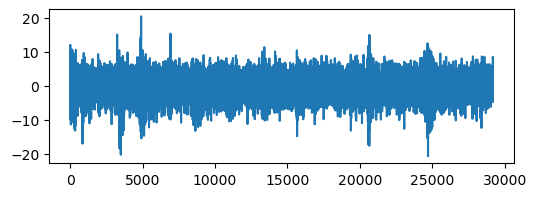

In [335]:
# 你的参数
from scipy.signal import butter, filtfilt, iirnotch

fs = 250    # 采样率
low = 5     # 低频截止
high = 90    # 高频截止
order = 4
f0 = 50.0            # 工频 Hz，50 或 60
Q = 30.0             # 品质因数，越大陷波越窄

# 设计陷波滤波器
# 直接滤波，不写额外函数
b, a = butter(order, [low/(fs/2), high/(fs/2)], btype='band')
b2, a2 = iirnotch(f0, Q, fs)

num_trials = len(trials) - 1
eeg_seg = [[] for i in range(num_channels)]
for i in range(num_channels):
    eeg_seg[i] = eeg[i][trials[0][0]:trials[num_trials_train-1][1]]
    eeg_seg[i] = filtfilt(b, a, eeg_seg[i])
    eeg_seg[i] = filtfilt(b2, a2, eeg_seg[i])
    eeg_seg[i] = eeg_seg[i] - np.mean(eeg_seg[i])
    eeg_seg[i] = eeg_seg[i] / np.var(eeg_seg[i]) *  1000
print(eeg_seg[0])
print(len(eeg_seg[0]))
plt.figure(figsize=(6, 2))
plt.plot(eeg_seg[2])

In [336]:
eeg_trials = []
eeg_labels = []
eeg_trials_class = []
eeg_labels_class = []
min_timepoints = 1000
for trial_test in range(num_trials_train):
    for i in range(num_channels):
        blink_timepoints = trials[trial_test][1]-trials[trial_test][0]
        # pause_timepoints = trials[trial_test+1][0]-trials[trial_test][1]
        # min_timepoints_trail = min(blink_timepoints, pause_timepoints)
        min_timepoints = min(min_timepoints, blink_timepoints)


for trial_test in range(num_trials_train):
    eeg_test_blink = [[] for _ in range(num_channels)]
    eeg_test_pause = [[] for _ in range(num_channels)]
    # print(f"Trial {trial_test}:")
    classid = trial_test % num_freqs
    for i in range(num_channels):
        eeg_test_blink[i] = eeg[i][trials[trial_test][0]: trials[trial_test][1]]
        eeg_test_blink[i] = filtfilt(b, a, eeg_test_blink[i])
        eeg_test_blink[i] = filtfilt(b2, a2, eeg_test_blink[i])
        eeg_test_blink[i] = eeg_test_blink[i] - np.mean(eeg_test_blink[i])
        eeg_test_blink[i] = eeg_test_blink[i] / np.var(eeg_test_blink[i]) *  1000
        
        # eeg_test_pause[i] = eeg[i][trials[trial_test][1]: trials[trial_test+1][0]]
        # eeg_test_pause[i] = eeg_test_pause[i] - np.mean(eeg_test_pause[i])
        # eeg_test_pause[i] = eeg_test_pause[i] / np.var(eeg_test_pause[i]) *  1000
        
        eeg_test_blink[i] = eeg_test_blink[i][:min_timepoints]
        # eeg_test_pause[i] = eeg_test_pause[i][:min_timepoints]
        
    eeg_trials_class.append(eeg_test_blink)
    eeg_labels_class.append(classid)
    
    if classid == num_freqs-1:
        eeg_trials.append(eeg_trials_class)
        eeg_labels.append(eeg_labels_class)
        eeg_trials_class = []
        eeg_labels_class = []

np.save('eeg_trials.npy', eeg_trials)
np.save('eeg_labels.npy', eeg_labels)

# from scipy.io import savemat
# savemat(f'eeg_data_{txt}.mat', {
#     'eeg': np.array(eeg_trials).transpose(1, 2, 3, 0),
# })
print(np.array(eeg_trials).shape) #(block, freq, channel, time)

(6, 4, 8, 498)


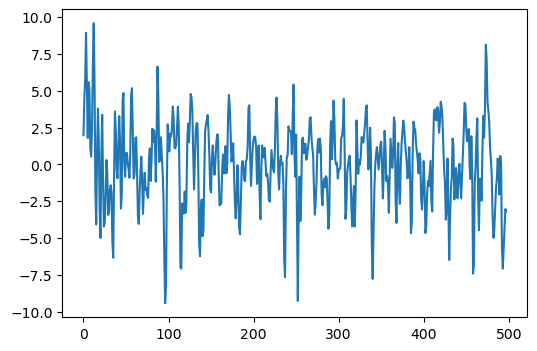

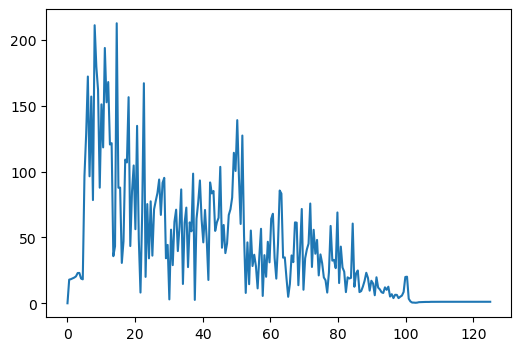

In [337]:
block, freq, channel = 1, 3, 2
fs = 250

samples = eeg_trials[block][freq][channel]
plt.figure(figsize=(6, 4))
plt.plot(samples)

freqs = np.fft.rfftfreq(len(samples), 1/fs)
spectrum = np.abs(np.fft.rfft(samples))
plt.figure(figsize=(6, 4))
plt.plot(freqs, spectrum)

### ICA

In [338]:
from sklearn.decomposition import FastICA, PCA
# S = np.array(eeg_trials[block][freq]).T
# ica = FastICA(n_components=num_components)
# D = ica.fit_transform(S)

var_ratio = 0.95
S = np.array(eeg_trials[block][freq]).T
pca = PCA(n_components=var_ratio)
D = pca.fit_transform(S)
print(D.shape)
num_components = D.shape[1]

(498, 3)


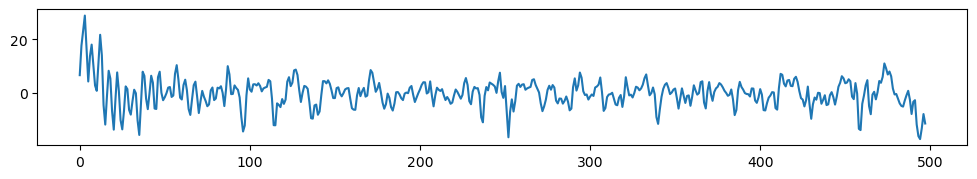

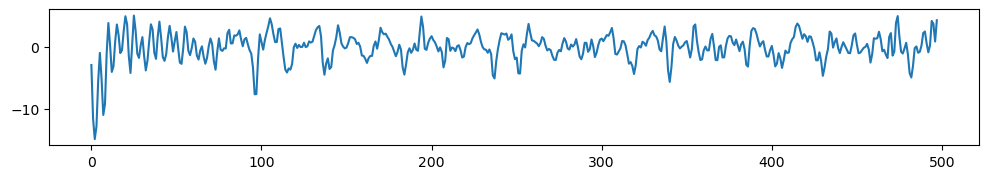

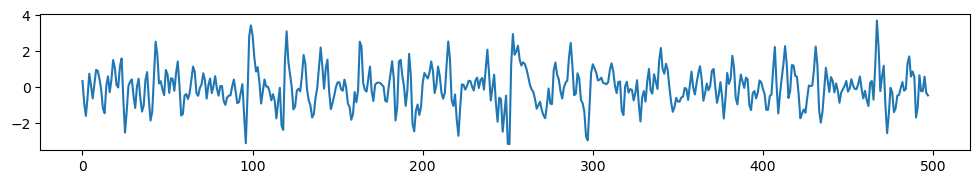

In [339]:
for i in range(num_components):
    plt.figure(figsize=(12, 6))
    plt.subplot(num_components, 1, i + 1)
    plt.plot(D[:, i])

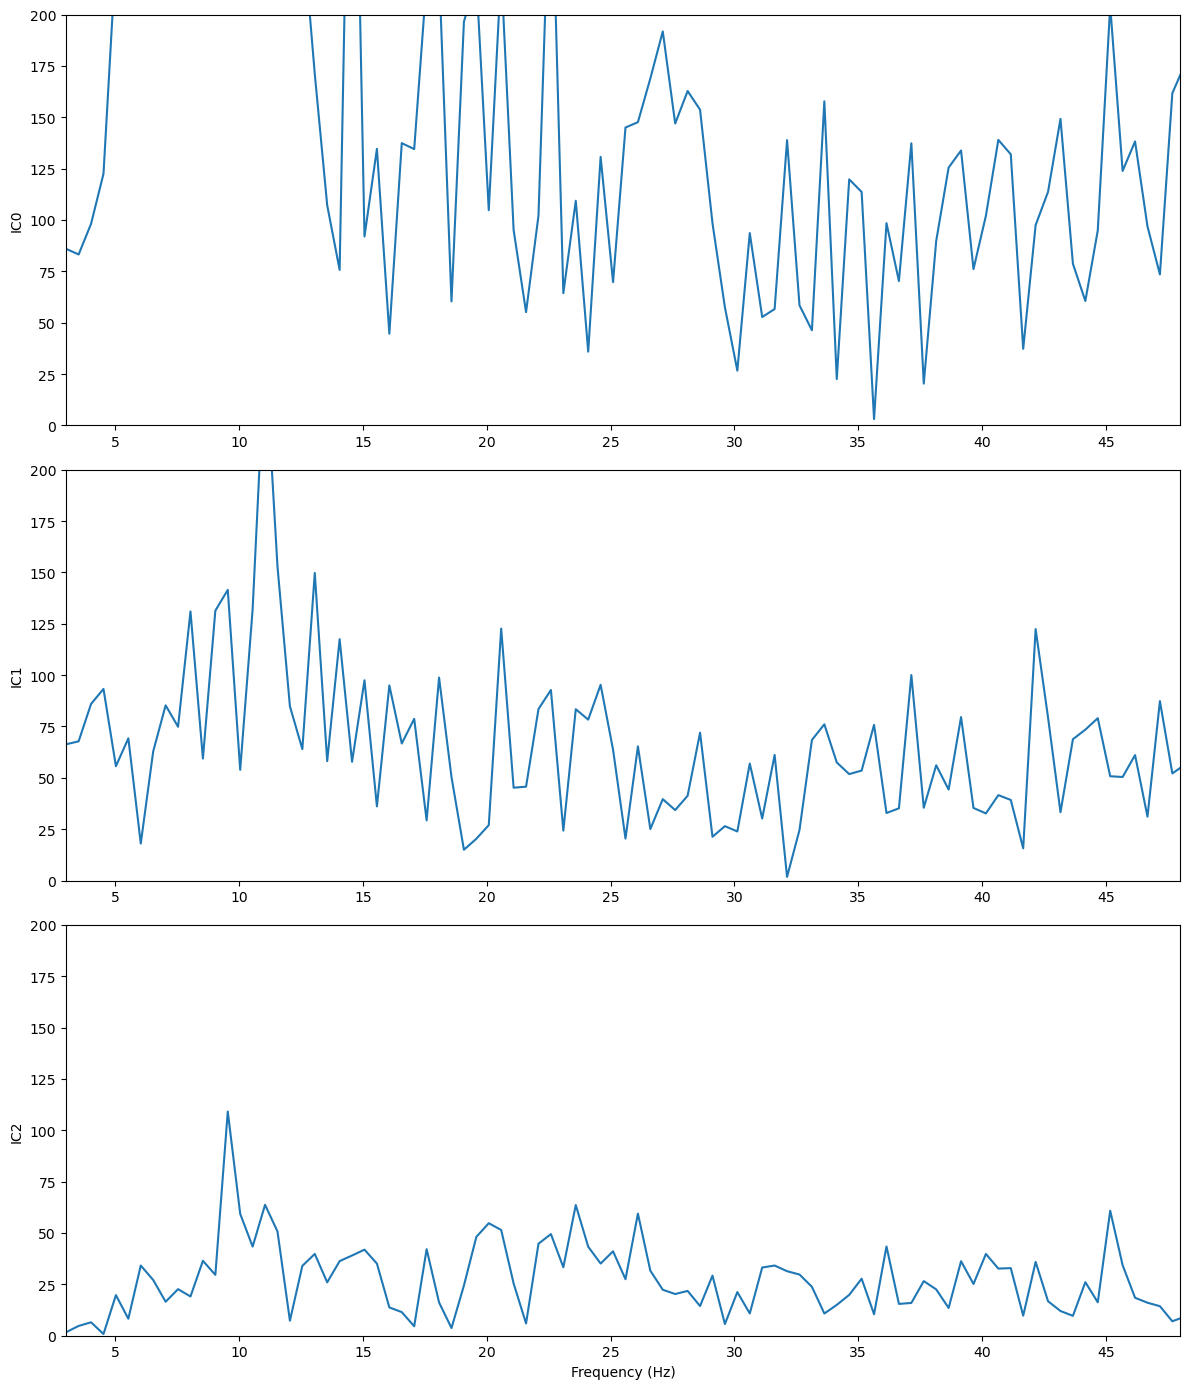

In [340]:
from scipy import signal

fs = 250  # 你的采样率，改成实际的

plt.figure(figsize=(12, 14))
for i in range(num_components):
    plt.subplot(num_components, 1, i + 1)
    x = D[:, i]
    
    freqs = np.fft.rfftfreq(len(x), 1/fs)
    spectrum = np.abs(np.fft.rfft(x))
    
    plt.plot(freqs, spectrum)
    plt.xlim(3, 48)  # EEG 只看 0-50 Hz
    plt.ylabel(f'IC{i}')
    plt.ylim(0, 200)
    
plt.xlabel('Frequency (Hz)')
plt.tight_layout()
plt.show()

In [341]:
len(eeg_trials[0][0][0])

498

In [342]:
eeg_trials = []
eeg_labels = []

min_timepoints = 1000  # 可以根据最短 trial 自动调整

# 计算最小长度
for trial_test in range(num_trials_train):
    for i in range(num_channels):
        blink_timepoints = trials[trial_test][1]-trials[trial_test][0]
        min_timepoints = min(min_timepoints, blink_timepoints)

num_blocks = num_trials_train // num_freqs

for block in range(num_blocks):
    eeg_trials_block = []
    eeg_labels_block = []

    for freq_idx in range(num_freqs):
        trial_test = block*num_freqs + freq_idx
        classid = trial_test % num_freqs

        eeg_trial = []
        for i in range(num_channels):
            x = eeg[i][trials[trial_test][0]:trials[trial_test][1]]
            x = filtfilt(b, a, x)
            x = filtfilt(b2, a2, x)
            x = x - np.mean(x)
            x = x / np.var(x) * 1000
            x = x[:min_timepoints]
            eeg_trial.append(x)

        eeg_trial = np.array(eeg_trial)  # [channel x time]
        pca = PCA(n_components=min(num_channels, min_timepoints))
        eeg_trial = pca.fit_transform(eeg_trial.T).T  # [components x time]

        eeg_trials_block.append(eeg_trial.astype(np.float32))
        eeg_labels_block.append(classid)

    # 将每个 block 的 freq 维度堆叠
    eeg_trials_block = np.stack(eeg_trials_block, axis=0)  # [freq x channel x time]
    eeg_labels_block = np.array(eeg_labels_block)

    eeg_trials.append(eeg_trials_block)
    eeg_labels.append(eeg_labels_block)

# 堆叠 block 维度
eeg_trials = np.stack(eeg_trials, axis=0)  # [block x freq x channel x time]
eeg_labels = np.stack(eeg_labels, axis=0)  # [block x freq]


from scipy.io import savemat
savemat(f'eeg_data_{txt}.mat', {
    'eeg': np.array(eeg_trials).transpose(1, 2, 3, 0),
})
print(eeg_trials.shape, eeg_labels.shape)
print(f'eeg_data_{txt}.mat')
# -> (block, freq, channel, time), 4D

(6, 4, 8, 498) (6, 4)
eeg_data_four_610_ssvep.mat


In [343]:
# D_recon = np.zeros_like(D)  # 形状: (23190, 7)
# D_recon[:, 1] = D[:, 1]  # 只保留第2个独立成分
# D_reconstructed = ica.inverse_transform(D_recon)  # 形状: (23190, 1)


In [344]:
# fs = 250  # 你的采样率，改成实际的

# plt.figure(figsize=(12, 7))
# for i in range(num_components):
#     plt.subplot(num_components, 1, i + 1)
#     x = D_reconstructed[:, i]
    
#     freqs = np.fft.rfftfreq(len(x), 1/fs)
#     spectrum = np.abs(np.fft.rfft(x))
    
#     plt.plot(freqs, spectrum)
#     plt.xlim(3, 48)  # EEG 只看 0-50 Hz
#     plt.ylabel(f'IC{i}')
#     plt.ylim(0, 10)
    
# plt.xlabel('Frequency (Hz)')
# plt.tight_layout()
# plt.show()

In [345]:
# for i in range(len(num_trials)):
#     eeg_trial = eeg_seg[0][trials[i][0]:trials[i][1]]